In [4]:
!pip install pandas numpy matplotlib seaborn scikit-learn scipy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [6]:
df = pd.read_csv("Wholesale customers data.csv")

print(df.head())
print(df.shape)
print(df.info())

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185
(440, 8)
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen    

In [7]:
X = df[['Fresh', 'Milk', 'Grocery',
        'Frozen', 'Detergents_Paper', 'Delicassen']]

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

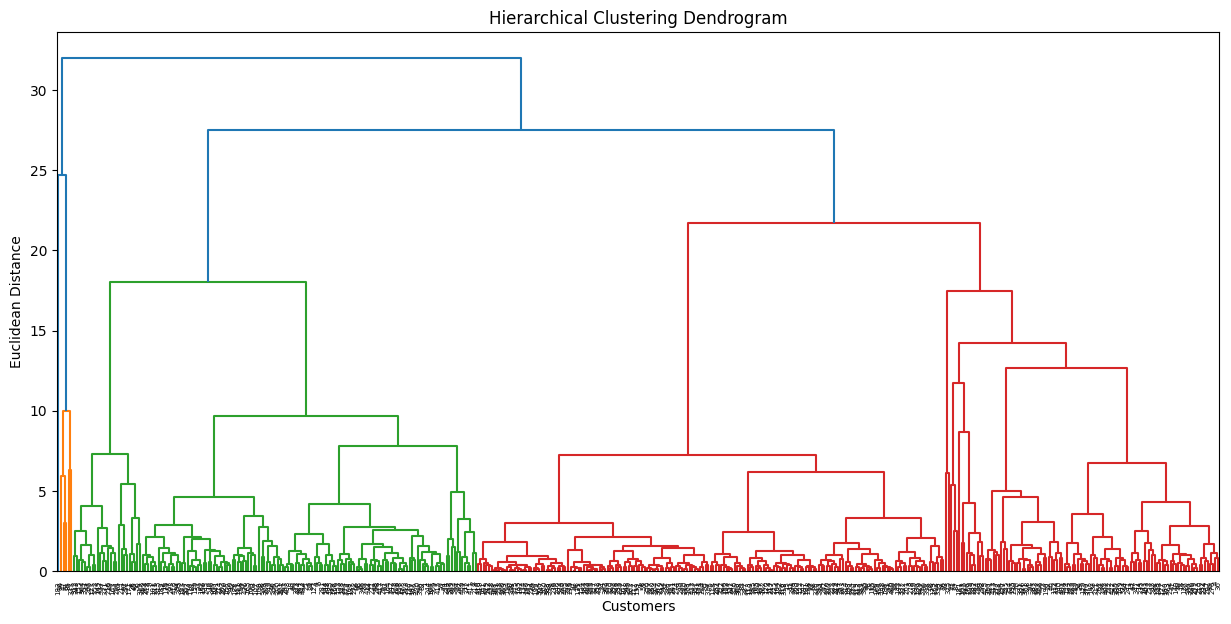

In [9]:
plt.figure(figsize=(15, 7))

linked = linkage(X_scaled, method='ward')

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")

plt.show()

In [15]:
model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

clusters = model.fit_predict(X_scaled)

df['Cluster'] = clusters

print(df[['Fresh', 'Milk', 'Grocery', 'Cluster']].head(10))

   Fresh   Milk  Grocery  Cluster
0  12669   9656     7561        0
1   7057   9810     9568        0
2   6353   8808     7684        0
3  13265   1196     4221        4
4  22615   5410     7198        2
5   9413   8259     5126        0
6  12126   3199     6975        0
7   7579   4956     9426        0
8   5963   3648     6192        4
9   6006  11093    18881        0


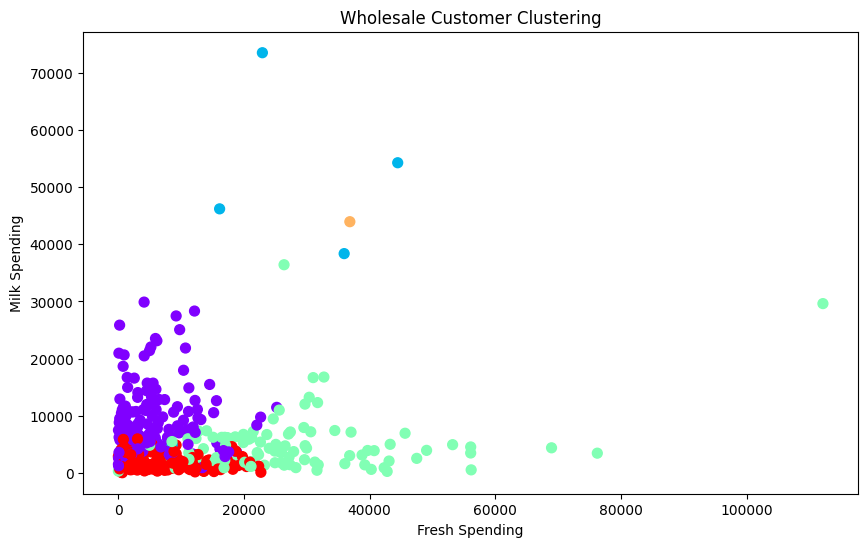

In [16]:


plt.figure(figsize=(10, 6))

plt.scatter(
    df['Fresh'],
    df['Milk'],
    c=df['Cluster'],
    cmap='rainbow',
    s=50
)

plt.xlabel("Fresh Spending")
plt.ylabel("Milk Spending")

plt.title("Wholesale Customer Clustering")

plt.show()

In [12]:
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", score)

Silhouette Score: 0.7924572758342273


In [13]:
print(df.groupby('Cluster')[
    ['Fresh', 'Milk', 'Grocery',
     'Frozen', 'Detergents_Paper', 'Delicassen']
].mean())

                Fresh          Milk       Grocery       Frozen  \
Cluster                                                          
0        11786.334101   5274.433180   7306.523041  2999.852535   
1        27477.000000  43542.166667  54588.500000  8285.666667   

         Detergents_Paper    Delicassen  
Cluster                                  
0             2575.453917   1404.276498  
1            25018.333333  10247.833333  


In [14]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

for k in range(2, 8):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(
        "Clusters:", k,
        "Silhouette Score:", round(score, 4)
    )

Clusters: 2 Silhouette Score: 0.7925
Clusters: 3 Silhouette Score: 0.2646
Clusters: 4 Silhouette Score: 0.267
Clusters: 5 Silhouette Score: 0.2399
Clusters: 6 Silhouette Score: 0.2342
Clusters: 7 Silhouette Score: 0.2441
